# Task A: play models

Every model is a registered `ScoringModel`, built from its `[models.<name>]` section in
`config.toml` and trained on `train_tables(t, "play")`, the same code `make train` runs.
Scored on the cached `play_valid_candidates`; test is touched once (§3), as a leak check,
and again only for the final numbers.

The final BPR is trained on *owned* games as positives, which predicts play better than
training on played games alone (§5).

In [1]:
%load_ext autoreload
%autoreload 2

import itertools
import time

import matplotlib.pyplot as plt
import pandas as pd

from assignment_2.modules.config import get_config
from assignment_2.modules.core import compare, evaluate_ranking
from assignment_2.modules.core.plots import save, use_style
from assignment_2.modules.data import load_prepped, train_tables
from assignment_2.modules.data.prep import prepped_dir
from assignment_2.modules.models import build

use_style()
get_config.cache_clear()
cfg = get_config()
t = load_prepped(cfg)
data = train_tables(t, "play")
cand = t["play_valid_candidates"]
K, N_BOOT = 10, 1000
GRIDS = prepped_dir(cfg)  # grid CSVs live next to the cache they were run on
print(f"sample={cfg.sample.tag}  {cand.user_id.nunique():,} validation users")
print("bpr config:", cfg.params("bpr"))

sample=users_0.1  5,946 validation users
bpr config: {'factors': 64, 'learning_rate': 0.01, 'regularization': 0.01, 'iterations': 100, 'positives': 'owned'}


## 1. Fit and score every task A model
Each model at its `config.toml` settings (BPR: the final setup from §5, `FINAL`).

In [2]:
MODELS_A = ["item_knn_rank", "user_knn_rank", "bpr"]

models = {name: build(name, cfg).fit(data) for name in MODELS_A}
summaries, per_user = {}, {}
for name, model in models.items():
    summaries[name], per_user[name] = evaluate_ranking(
        cand, model.predict(cand), k=K, n_boot=N_BOOT, seed=cfg.seed
    )


def fmt(summary: dict) -> dict:
    return {m: f"{v.value:.3f} [{v.ci_low:.3f}, {v.ci_high:.3f}]" for m, v in summary.items()}


pd.DataFrame({name: fmt(s) for name, s in summaries.items()}).T

,hit@10,ndcg@10,mrr
item_knn_rank,"0.497 [0.484, 0.510]","0.303 [0.294, 0.312]","0.264 [0.255, 0.273]"
user_knn_rank,"0.440 [0.427, 0.453]","0.268 [0.259, 0.277]","0.237 [0.229, 0.245]"
bpr,"0.619 [0.606, 0.631]","0.388 [0.379, 0.398]","0.335 [0.325, 0.344]"


**Check:** `item_knn_rank` must reproduce `explore_play`'s item kNN (Jaccard) exactly.

In [3]:
assert abs(summaries["item_knn_rank"]["hit@10"].value - 0.497) < 0.001

## 2. Is BPR's gain real?
Paired bootstrap: Δ = first − second, 95% interval over the same resampled users.

In [4]:
def diff_table(pairs: list[tuple[str, str]], pu: dict, metrics=("hit@10", "ndcg@10", "mrr")):
    rows = {}
    for a, b in pairs:
        for m in metrics:
            d = compare(pu[a][m], pu[b][m], n_boot=N_BOOT, seed=cfg.seed)
            rows[(f"{a} − {b}", m)] = {"difference": d.value, "ci low": d.ci_low,
                                       "ci high": d.ci_high, "real?": d.ci_low > 0 or d.ci_high < 0}
    return pd.DataFrame(rows).T.round(4)


diff_table([("bpr", "item_knn_rank"), ("bpr", "user_knn_rank")], per_user)

difference    ci low   ci high real?
bpr − item_knn_rank hit@10    0.121763  0.105954  0.138581  True
                    ndcg@10   0.085429  0.074287  0.096845  True
                    mrr       0.070523  0.059876  0.080988  True
bpr − user_knn_rank hit@10     0.17928  0.164144  0.195774  True
                    ndcg@10   0.120558  0.110091  0.131992  True
                    mrr       0.097583  0.087144  0.108383  True

## 3. Leak checks (before trusting the gain)
1. No held-out (user, game) pair appears anywhere in training, at any playtime (so neither
   "played" nor "owned" positives can include one).
2. Test scores about the same as validation. Test is looked at **once here**, as a sanity
   check; all tuning stays on validation.

In [5]:
held = pd.concat([t["play_valid"], t["play_test"]])
assert held.merge(data.interactions, on=["user_id", "item_id"]).empty, "held-out pair in training"

cand_test = t["play_test_candidates"]
s_test, _ = evaluate_ranking(cand_test, models["bpr"].predict(cand_test),
                             k=K, n_boot=N_BOOT, seed=cfg.seed)
pd.DataFrame({"valid": {m: v.value for m, v in summaries["bpr"].items()},
              "test": {m: v.value for m, v in s_test.items()}}).round(3)

,valid,test
hit@10,0.619,0.615
ndcg@10,0.388,0.382
mrr,0.335,0.328


## 4. Tuning BPR (validation only)

Every grid starts from the **untuned defaults** below, not from `config.toml`, so the
notebook reruns to the same tables even after the tuned values are written to the config.
Each setting is fit with 3 seeds; the seed std shows training noise (cells within ~2 std
are tied). Every row is saved to `grid_bpr_*.csv`.

In [6]:
UNTUNED = {"factors": 64, "learning_rate": 0.01, "regularization": 0.01,
           "iterations": 100, "positives": "played"}
SEEDS = (0, 1, 2)


def fit_score(params: dict, seed: int) -> dict[str, float]:
    """Fit BPR at UNTUNED + params with this seed; validation metrics as plain numbers."""
    model = build("bpr", cfg, **{**UNTUNED, **params}, seed=seed).fit(data)
    s, _ = evaluate_ranking(cand, model.predict(cand), k=K, n_boot=100, seed=cfg.seed)
    return {m: v.value for m, v in s.items()}


def run_grid(grid: dict[str, list], seeds=SEEDS) -> pd.DataFrame:
    """One row per (setting, seed): settings, validation metrics, fit time."""
    rows = []
    for values in itertools.product(*grid.values()):
        params = dict(zip(grid, values))
        for seed in seeds:
            start = time.perf_counter()
            rows.append({**params, "seed": seed, **fit_score(params, seed),
                         "seconds": round(time.perf_counter() - start, 1)})
    return pd.DataFrame(rows)


def summarize(g: pd.DataFrame, by, metrics=("hit@10", "ndcg@10")) -> pd.DataFrame:
    return g.groupby(by)[list(metrics)].agg(["mean", "std"]).round(4)

### 4.0 Seed noise at the untuned defaults

In [7]:
g0 = run_grid({})
g0.to_csv(GRIDS / "grid_bpr_stage0_seeds.csv", index=False)
g0[["hit@10", "ndcg@10", "mrr"]].agg(["mean", "std"]).round(4)

,hit@10,ndcg@10,mrr
mean,0.5719,0.3482,0.2978
std,0.0012,0.0002,0.0008


### 4.1 Factors × regularization (coarse)

In [8]:
g1 = run_grid({"factors": [32, 64, 128], "regularization": [0.001, 0.01, 0.1]}, seeds=(0,))
g1.to_csv(GRIDS / "grid_bpr_stage1.csv", index=False)
g1.pivot(index="factors", columns="regularization", values="ndcg@10").round(4)

regularization,0.001,0.010,0.100
factors,,,
32,0.2749,0.3485,0.2672
64,0.2661,0.3482,0.2638
128,0.2672,0.3509,0.2624


### 4.2 Regularization (fine), 64 factors

In [9]:
g1b = run_grid({"regularization": [0.003, 0.005, 0.01, 0.02, 0.03]})
g1b.to_csv(GRIDS / "grid_bpr_stage1b.csv", index=False)
summarize(g1b, "regularization")

hit@10         ndcg@10        
                  mean     std    mean     std
regularization                                
0.003           0.4952  0.0062  0.2951  0.0008
0.005           0.5256  0.0036  0.3149  0.0007
0.010           0.5719  0.0012  0.3482  0.0002
0.020           0.5849  0.0024  0.3618  0.0007
0.030           0.5709  0.0004  0.3512  0.0008

### 4.3 Factors at regularization 0.02

In [10]:
g2a = run_grid({"factors": [32, 64, 128, 256], "regularization": [0.02]})
g2a.to_csv(GRIDS / "grid_bpr_stage2a.csv", index=False)
summarize(g2a, "factors", metrics=("hit@10", "ndcg@10", "seconds"))

hit@10         ndcg@10         seconds        
           mean     std    mean     std    mean     std
factors                                                
32       0.5854  0.0033  0.3631  0.0012  2.2667  0.0577
64       0.5849  0.0024  0.3618  0.0007  2.8333  0.1528
128      0.5811  0.0035  0.3612  0.0028  4.1667  0.2082
256      0.5790  0.0031  0.3581  0.0029  6.7333  0.3215

### 4.4 Iterations (32 factors, regularization 0.02)

In [11]:
g2b = run_grid({"factors": [32], "regularization": [0.02], "iterations": [50, 100, 200, 400]})
g2b.to_csv(GRIDS / "grid_bpr_stage2b.csv", index=False)
summarize(g2b, "iterations", metrics=("hit@10", "ndcg@10", "seconds"))

hit@10         ndcg@10         seconds        
              mean     std    mean     std    mean     std
iterations                                                
50          0.5381  0.0045  0.3295  0.0021  1.4000  0.0000
100         0.5854  0.0033  0.3631  0.0012  2.3333  0.1528
200         0.5825  0.0040  0.3547  0.0028  4.1667  0.0577
400         0.5664  0.0008  0.3390  0.0016  7.7667  0.1528

### 4.5 Iterations × regularization (do longer runs want more regularization?)

In [12]:
g2c = run_grid({"factors": [32], "iterations": [100, 200], "regularization": [0.02, 0.03, 0.05]})
g2c.to_csv(GRIDS / "grid_bpr_stage2c.csv", index=False)
(g2c.groupby(["iterations", "regularization"])["ndcg@10"]
    .agg(["mean", "std"]).unstack("regularization").round(4))

mean                     std                
regularization    0.02    0.03    0.05    0.02    0.03    0.05
iterations                                                    
100             0.3631  0.3541  0.3268  0.0012  0.0006  0.0015
200             0.3547  0.3620  0.3512  0.0028  0.0019  0.0012

### 4.6 Learning rate (32 factors, regularization 0.02, 100 iterations)

In [13]:
g3 = run_grid({"factors": [32], "regularization": [0.02], "iterations": [100],
               "learning_rate": [0.005, 0.01, 0.02, 0.05]})
g3.to_csv(GRIDS / "grid_bpr_stage3.csv", index=False)
summarize(g3, "learning_rate")

hit@10         ndcg@10        
                 mean     std    mean     std
learning_rate                                
0.005          0.5451  0.0026  0.3331  0.0016
0.010          0.5854  0.0033  0.3631  0.0012
0.020          0.5787  0.0030  0.3503  0.0015
0.050          0.5482  0.0049  0.3206  0.0038

**Best "played" setup (`PLAYED_BEST`):** 32 factors, regularization 0.02, 100 iterations,
learning rate 0.01. What did tuning buy, on the same users?

In [14]:
# Best "played" setup from §4.1–4.6 (the base for §5's grids and the "played" side of the
# ablation), and the final setup written to [models.bpr] after §5.
PLAYED_BEST = {"factors": 32, "regularization": 0.02, "iterations": 100,
               "learning_rate": 0.01, "positives": "played"}
FINAL = {"factors": 64, "regularization": 0.01, "iterations": 100,
         "learning_rate": 0.01, "positives": "owned"}
assert all(cfg.params("bpr")[k] == v for k, v in FINAL.items()), "config.toml ≠ FINAL"

# Tuning "played": best vs untuned, on the same users
for name, params in {"bpr (played, tuned)": PLAYED_BEST, "bpr (untuned)": UNTUNED}.items():
    model = build("bpr", cfg, **params).fit(data)
    _, per_user[name] = evaluate_ranking(cand, model.predict(cand),
                                         k=K, n_boot=N_BOOT, seed=cfg.seed)
diff_table([("bpr (played, tuned)", "bpr (untuned)")], per_user)

difference    ci low   ci high  \
bpr (played, tuned) − bpr (untuned) hit@10      0.0111  0.002859  0.020018   
                                    ndcg@10   0.013358  0.008227  0.018762   
                                    mrr       0.013786  0.008207  0.019383   

                                            real?  
bpr (played, tuned) − bpr (untuned) hit@10   True  
                                    ndcg@10  True  
                                    mrr      True

## 5. Positives: every owned game vs only games played ≥ 2 h
"owned" has ~3× the positives, so its regularization (5.1), then factors and iterations
(5.2), are re-tuned before the final comparison (5.3).

### 5.1 Regularization for owned positives

In [15]:
g4b = run_grid({**{k: [v] for k, v in PLAYED_BEST.items()}, "positives": ["owned"],
                "regularization": [0.005, 0.0075, 0.01, 0.02, 0.03]})
g4b.to_csv(GRIDS / "grid_bpr_stage4b.csv", index=False)
summarize(g4b, "regularization")

hit@10         ndcg@10        
                  mean     std    mean     std
regularization                                
0.0050          0.6042  0.0022  0.3758  0.0009
0.0075          0.6114  0.0037  0.3819  0.0019
0.0100          0.6136  0.0037  0.3844  0.0021
0.0200          0.5995  0.0047  0.3741  0.0036
0.0300          0.5725  0.0024  0.3518  0.0017

### 5.2 Factors and iterations for owned positives
`g4c`: factors × iterations at reg 0.01. `g4d`: 64 vs 128 vs 256 (64 was the edge of `g4c`).

In [16]:
g4c = run_grid({"positives": ["owned"], "regularization": [0.01],
                "learning_rate": [0.01], "factors": [32, 64], "iterations": [100, 200, 300]})
g4c.to_csv(GRIDS / "grid_bpr_stage4c.csv", index=False)
(g4c.groupby(["factors", "iterations"])["ndcg@10"]
    .agg(["mean", "std"]).unstack("iterations").round(4))

mean                     std                
iterations     100     200     300     100     200     300
factors                                                   
32          0.3844  0.3843  0.3842  0.0021  0.0006  0.0047
64          0.3936  0.3921  0.3943  0.0024  0.0013  0.0036

In [17]:
g4d = run_grid({"positives": ["owned"], "regularization": [0.01], "learning_rate": [0.01],
                "iterations": [100], "factors": [64, 128, 256]})
g4d.to_csv(GRIDS / "grid_bpr_stage4d.csv", index=False)
summarize(g4d, "factors", metrics=("hit@10", "ndcg@10", "seconds"))

hit@10         ndcg@10          seconds        
           mean     std    mean     std     mean     std
factors                                                 
64       0.6265  0.0021  0.3936  0.0024   9.1000  0.2000
128      0.6254  0.0020  0.3932  0.0024  13.2000  0.3606
256      0.6243  0.0009  0.3928  0.0014  18.9333  1.2014

### 5.3 Final vs final: owned positives against the best "played" setup
`FINAL` (config.toml: owned, 64 factors, reg 0.01) against `PLAYED_BEST` (played, 32
factors, reg 0.02), each at its own best settings, on the same users. Δ = owned − played.

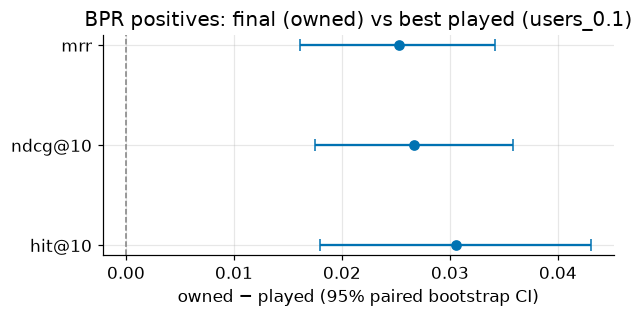

,value,ci_low,ci_high
hit@10,0.0306,0.0180,0.0431
ndcg@10,0.0267,0.0175,0.0358
mrr,0.0253,0.0161,0.0342


In [18]:
pu_pos = {
    "played": per_user["bpr (played, tuned)"],  # PLAYED_BEST, fit in §4.6
    "owned": per_user["bpr"],                   # FINAL, from config.toml (§1)
}
metrics = ["hit@10", "ndcg@10", "mrr"]
diffs = {m: compare(pu_pos["owned"][m], pu_pos["played"][m], n_boot=N_BOOT, seed=cfg.seed)
         for m in metrics}

fig, ax = plt.subplots(figsize=(6, 2.6))
y = range(len(metrics))
ax.errorbar([diffs[m].value for m in metrics], y,
            xerr=[[diffs[m].value - diffs[m].ci_low for m in metrics],
                  [diffs[m].ci_high - diffs[m].value for m in metrics]],
            fmt="o", capsize=4)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set(yticks=list(y), yticklabels=metrics,
       xlabel="owned − played (95% paired bootstrap CI)",
       title=f"BPR positives: final (owned) vs best played ({cfg.sample.tag})")
save(fig, "bpr_positives_ablation")
plt.show()

pd.DataFrame({m: vars(d) for m, d in diffs.items()}).T.round(4)

## 6. Takeaways
- `item_knn_rank` reproduces explore_play's item kNN (Hit@10 0.497), so the registered
  models match the notebook baselines.
- **Final BPR** (owned positives, 64 factors, reg 0.01, 100 iterations, lr 0.01; the
  library defaults apart from the positives): Hit@10 0.619 [0.606, 0.631], NDCG@10 0.388
  [0.379, 0.398], MRR 0.335. vs item kNN: ΔHit@10 +0.122 [+0.106, +0.139], ΔNDCG@10 +0.085
  [+0.074, +0.097]; vs user kNN: ΔHit@10 +0.179 [+0.164, +0.196].
- Where the gain comes from (ΔHit@10 over item kNN, paired bootstrap): BPR itself +0.080
  (untuned, played positives), tuning +0.011, owned positives +0.031.
- Tuning "played" (validation): regularization dominates (0.001 and 0.1 both lose ~0.08
  NDCG; peak at 0.02). Factors 32–128 tied (32 kept); 100 iterations is best and longer
  training overfits, unless regularization rises with it (200 / 0.03 ties 100 / 0.02).
  Learning rate 0.01. Seed noise ~0.001 NDCG.
- Positives: "owned" beats the best "played" setup: ΔHit@10 +0.031 [+0.018, +0.043],
  ΔNDCG@10 +0.027 [+0.018, +0.036], ΔMRR +0.025 [+0.016, +0.034]. With ~3× the positives
  it needs less regularization (0.01 vs 0.02) and supports a larger model (64 beats 32;
  64 = 128 = 256). Part of the gain is real preference signal (owned-but-unplayed games
  show taste; with "played" positives BPR can sample them as negatives); part is the
  protocol (the held-out game is always owned, the 99 negatives never are), so task A
  partly rewards predicting ownership.
- Leak checks pass: no held-out pair is in training, and test matches validation for
  every BPR checked (final: Hit@10 0.615 vs 0.619, NDCG 0.382 vs 0.388). No choice was
  made on test.